# Predicting Chronic Kidney Disease from clinical records

The UCI Chronic Kidney Disease dataset has 400 patients, 24 clinical attributes (blood tests, urine tests and
history) and a label saying whether the patient has CKD. 242 of the 400 records have at least one missing value.

This notebook cleans the data, explores it, and compares classical classifiers (with and without PCA/LDA) under a
leakage-free evaluation.

## Evaluation protocol

An earlier version of this notebook oversampled the minority class, scaled the data and fitted PCA/LDA on **all 400
rows before** splitting them into train and test. Oversampling first copies minority rows, so about a third of the
"test" rows were exact copies of training rows, and the scaler and PCA/LDA had already seen the test data. The scores
it reported were therefore optimistic.

This version:

1. **splits first**: a stratified 80/20 train/test split (`random_state=7`), before any preprocessing;
2. does exploratory analysis on the **training rows only**;
3. fits every preprocessing step (imputation, encoding, oversampling, scaling, PCA/LDA) **on training data only**,
   inside an `imblearn` pipeline, so cross-validation also refits them in every fold;
4. reports the **held-out test set** once, plus **repeated stratified 5-fold cross-validation** (5 x 5 = 25 fits) on
   all 400 rows. With only 80 test patients, one misclassification moves test accuracy by 1.25 points, so the
   cross-validated mean and spread are the more reliable numbers.

Label convention: **1 = CKD, 0 = not CKD**.

## Imports

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold, cross_validate,
                                     train_test_split)
from sklearn.naive_bayes import BernoulliNB, GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline

SEED = 7
sns.set_theme()

## Load and clean the data

In [2]:
def load_ckd(path="kidney_disease.csv"):
    """Load the UCI CKD data and repair its formatting problems."""
    df = pd.read_csv(path)
    # Some text cells carry stray tabs or spaces: 'ckd\t', '\tno', ' yes'.
    for col in df.columns:
        if pd.api.types.is_string_dtype(df[col]):
            df[col] = df[col].str.strip()
    # pcv, wc and rc are numeric but are stored as text because of '\t?' placeholders.
    for col in ["pcv", "wc", "rc"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")  # '?' becomes NaN
    return df


raw = pd.read_csv("kidney_disease.csv")
print("shape:", raw.shape)
print("stray-whitespace values:", {c: sorted(v for v in raw[c].dropna().unique() if isinstance(v, str) and v != v.strip())
                                   for c in raw.columns if pd.api.types.is_string_dtype(raw[c])})

df = load_ckd()
df.head(10)

shape: (400, 26)
stray-whitespace values: {'rbc': [], 'pc': [], 'pcc': [], 'ba': [], 'pcv': ['\t43', '\t?'], 'wc': ['\t6200', '\t8400', '\t?'], 'rc': ['\t?'], 'htn': [], 'dm': ['\tno', '\tyes', ' yes'], 'cad': ['\tno'], 'appet': [], 'pe': [], 'ane': [], 'classification': ['ckd\t']}


,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,44.0,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,38.0,6000.0,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31.0,7500.0,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35.0,7300.0,4.6,no,no,no,good,no,no,ckd
5,5,60.0,90.0,1.015,3.0,0.0,NaN,NaN,notpresent,notpresent,...,39.0,7800.0,4.4,yes,yes,no,good,yes,no,ckd
6,6,68.0,70.0,1.010,0.0,0.0,NaN,normal,notpresent,notpresent,...,36.0,NaN,NaN,no,no,no,good,no,no,ckd
7,7,24.0,NaN,1.015,2.0,4.0,normal,abnormal,notpresent,notpresent,...,44.0,6900.0,5.0,no,yes,no,good,yes,no,ckd
8,8,52.0,100.0,1.015,3.0,0.0,normal,abnormal,present,notpresent,...,33.0,9600.0,4.0,yes,yes,no,good,no,yes,ckd
9,9,53.0,90.0,1.020,2.0,0.0,abnormal,abnormal,present,notpresent,...,29.0,12100.0,3.7,yes,yes,no,poor,no,yes,ckd


In [3]:
print("missing values per column:")
print(df.isna().sum().sort_values(ascending=False).to_string())
print("\nrecords with at least one missing value:", df.isna().any(axis=1).sum(), "of", len(df))

missing values per column:
rbc               152
rc                131
wc                106
pot                88
sod                87
pcv                71
pc                 65
hemo               52
su                 49
sg                 47
al                 46
bgr                44
bu                 19
sc                 17
bp                 12
age                 9
pcc                 4
ba                  4
dm                  2
htn                 2
cad                 2
appet               1
ane                 1
pe                  1
id                  0
classification      0

records with at least one missing value: 242 of 400


In [4]:
NUMERIC = ["age", "bp", "sg", "al", "su", "bgr", "bu", "sc", "sod", "pot", "hemo", "pcv", "wc", "rc"]
CATEGORICAL = ["rbc", "pc", "pcc", "ba", "htn", "dm", "cad", "appet", "pe", "ane"]

X = df[NUMERIC + CATEGORICAL]
y = (df["classification"] == "ckd").astype(int)   # 1 = CKD

# The rows are sorted by class (ids 0-249 are CKD, 250-399 are not), so `id` must never be used as a feature.
print(df.groupby("classification")["id"].agg(["min", "max", "count"]))
for col in CATEGORICAL:
    print(f"{col:6s}", sorted(df[col].dropna().unique()))

                min  max  count
classification                 
ckd               0  249    250
notckd          250  399    150
rbc    ['abnormal', 'normal']
pc     ['abnormal', 'normal']
pcc    ['notpresent', 'present']
ba     ['notpresent', 'present']
htn    ['no', 'yes']
dm     ['no', 'yes']
cad    ['no', 'yes']
appet  ['good', 'poor']
pe     ['no', 'yes']
ane    ['no', 'yes']


## Train/test split (before anything is fitted)

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("train:", X_train.shape, "CKD / not CKD =", y_train.sum(), "/", (1 - y_train).sum())
print("test: ", X_test.shape, "CKD / not CKD =", y_test.sum(), "/", (1 - y_test).sum())

train: (320, 24) CKD / not CKD = 200 / 120
test:  (80, 24) CKD / not CKD = 50 / 30


## Exploratory analysis (training rows only)

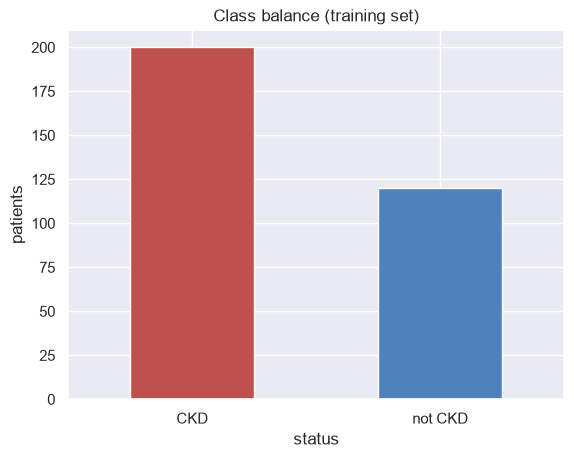

In [6]:
train_df = X_train.assign(status=y_train.map({1: "CKD", 0: "not CKD"}))
ax = train_df["status"].value_counts().plot.bar(rot=0, color=["#c0504d", "#4f81bd"])
ax.set_title("Class balance (training set)")
ax.set_ylabel("patients")
plt.show()

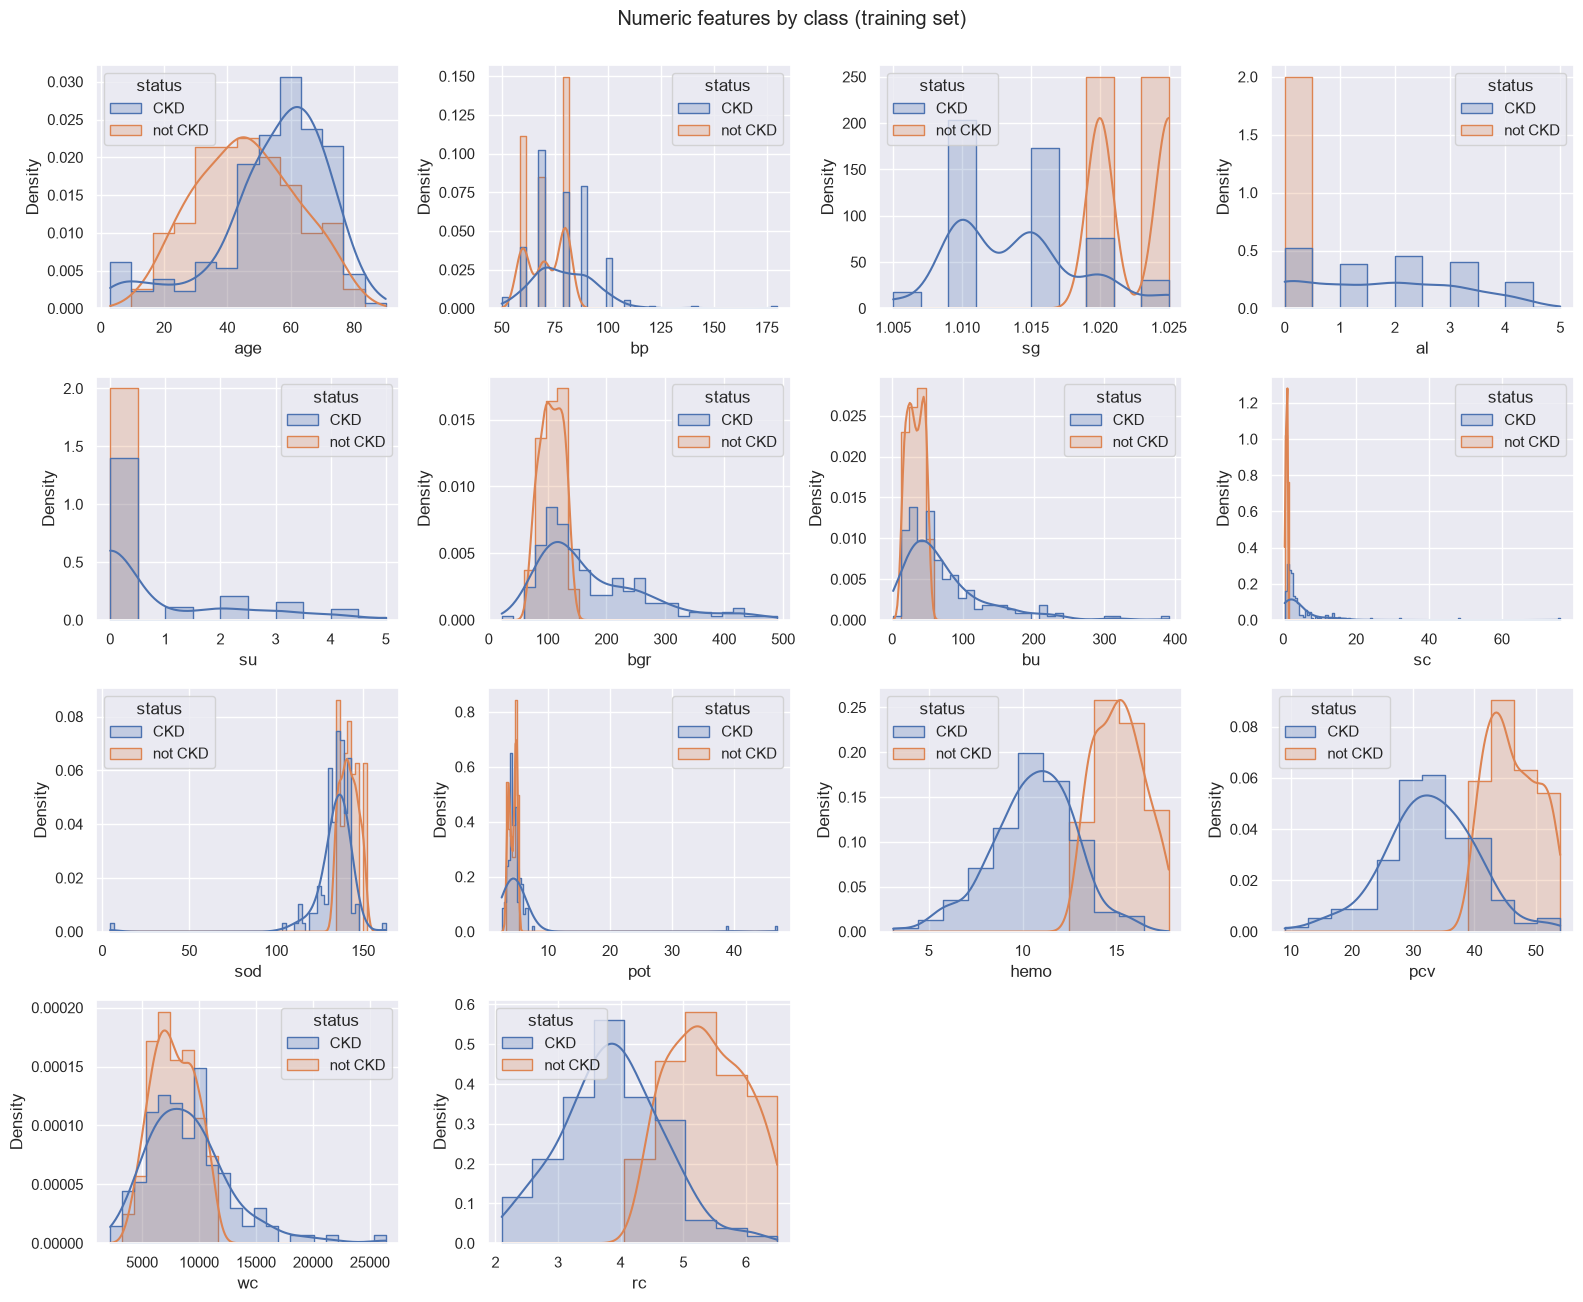

In [7]:
fig, axes = plt.subplots(4, 4, figsize=(16, 13))
for ax, col in zip(axes.ravel(), NUMERIC):
    sns.histplot(data=train_df, x=col, hue="status", kde=True, stat="density", common_norm=False,
                 element="step", ax=ax)
for ax in axes.ravel()[len(NUMERIC):]:
    ax.axis("off")
fig.suptitle("Numeric features by class (training set)", y=1.0)
plt.tight_layout()
plt.show()

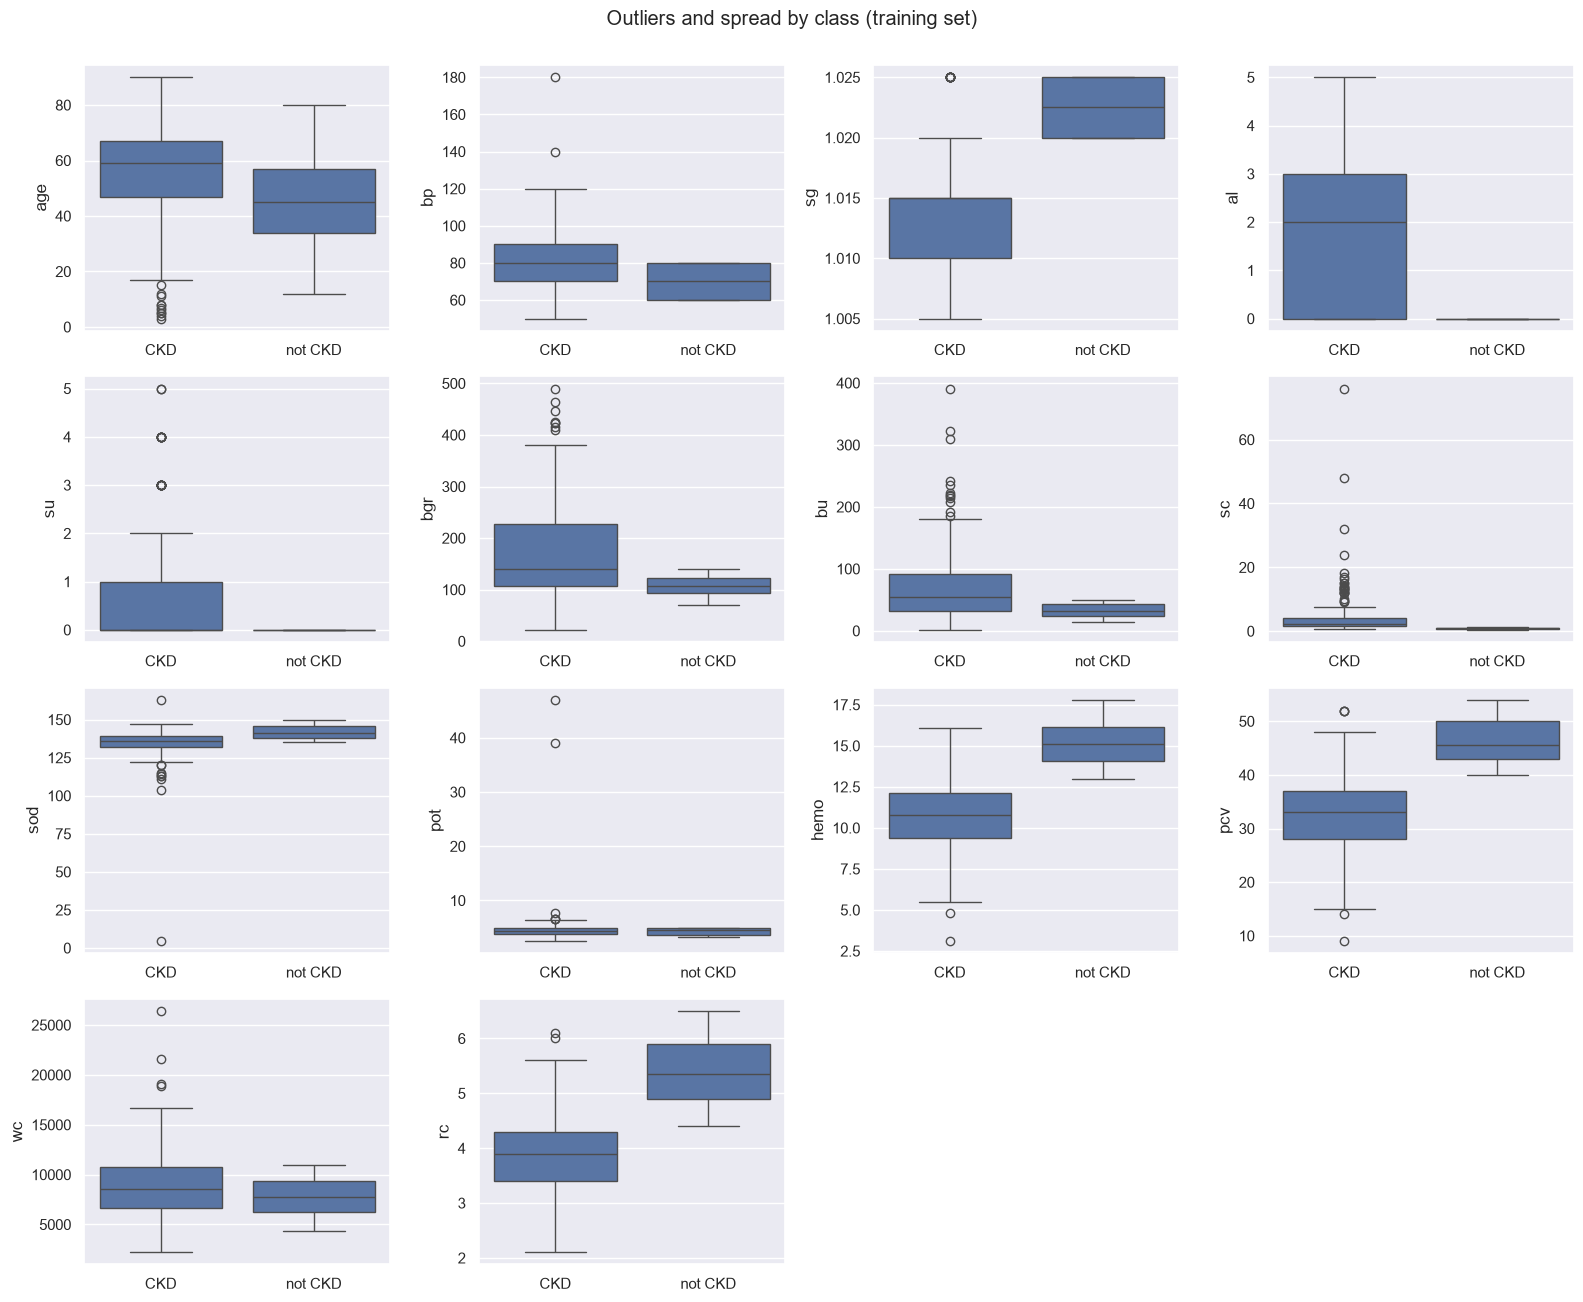

In [8]:
fig, axes = plt.subplots(4, 4, figsize=(16, 13))
for ax, col in zip(axes.ravel(), NUMERIC):
    sns.boxplot(data=train_df, x="status", y=col, ax=ax)
    ax.set_xlabel("")
for ax in axes.ravel()[len(NUMERIC):]:
    ax.axis("off")
fig.suptitle("Outliers and spread by class (training set)", y=1.0)
plt.tight_layout()
plt.show()

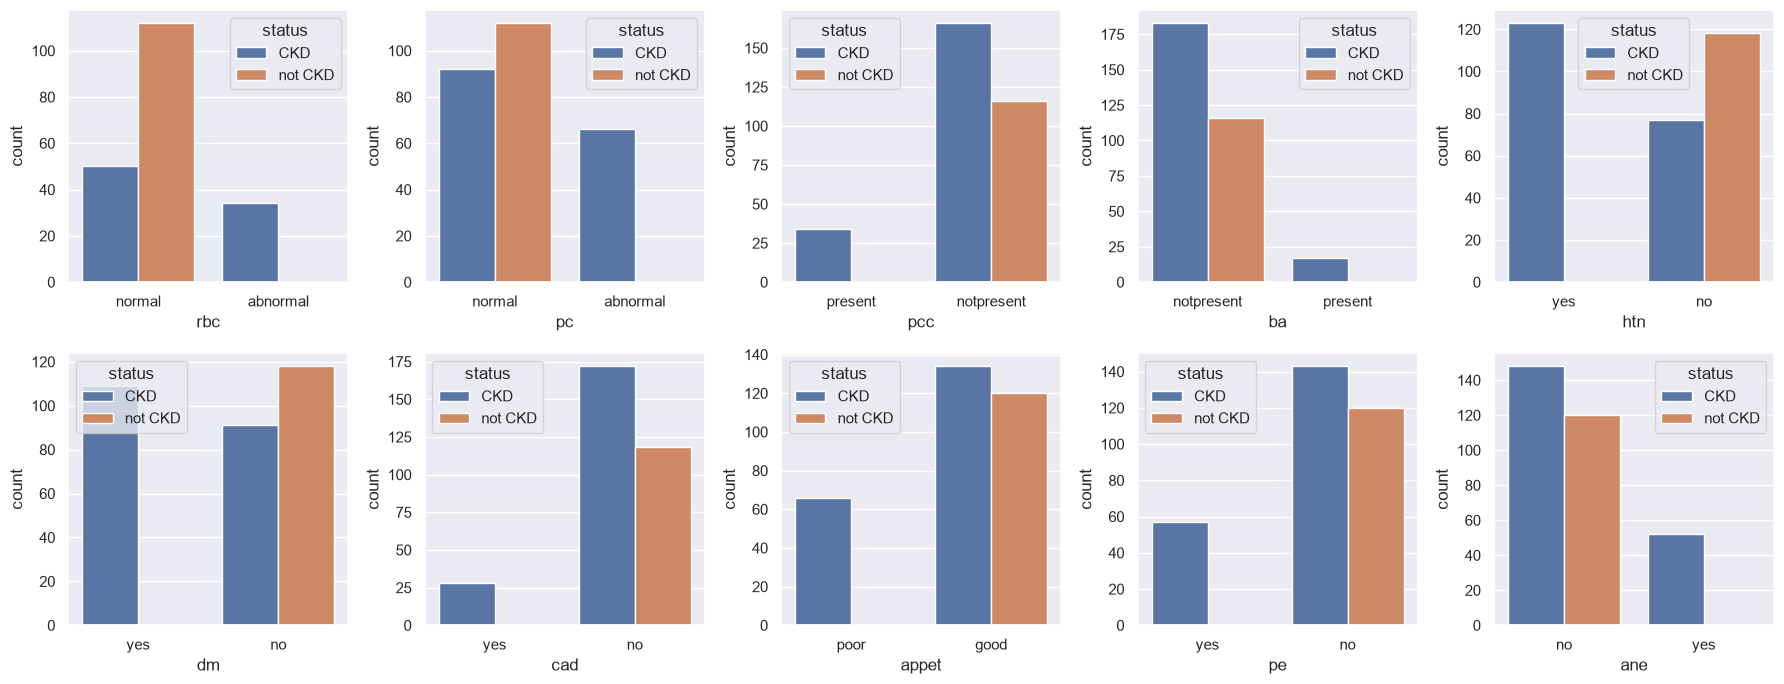

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, col in zip(axes.ravel(), CATEGORICAL):
    sns.countplot(data=train_df, x=col, hue="status", ax=ax)
    ax.set_xlabel(col)
plt.tight_layout()
plt.show()

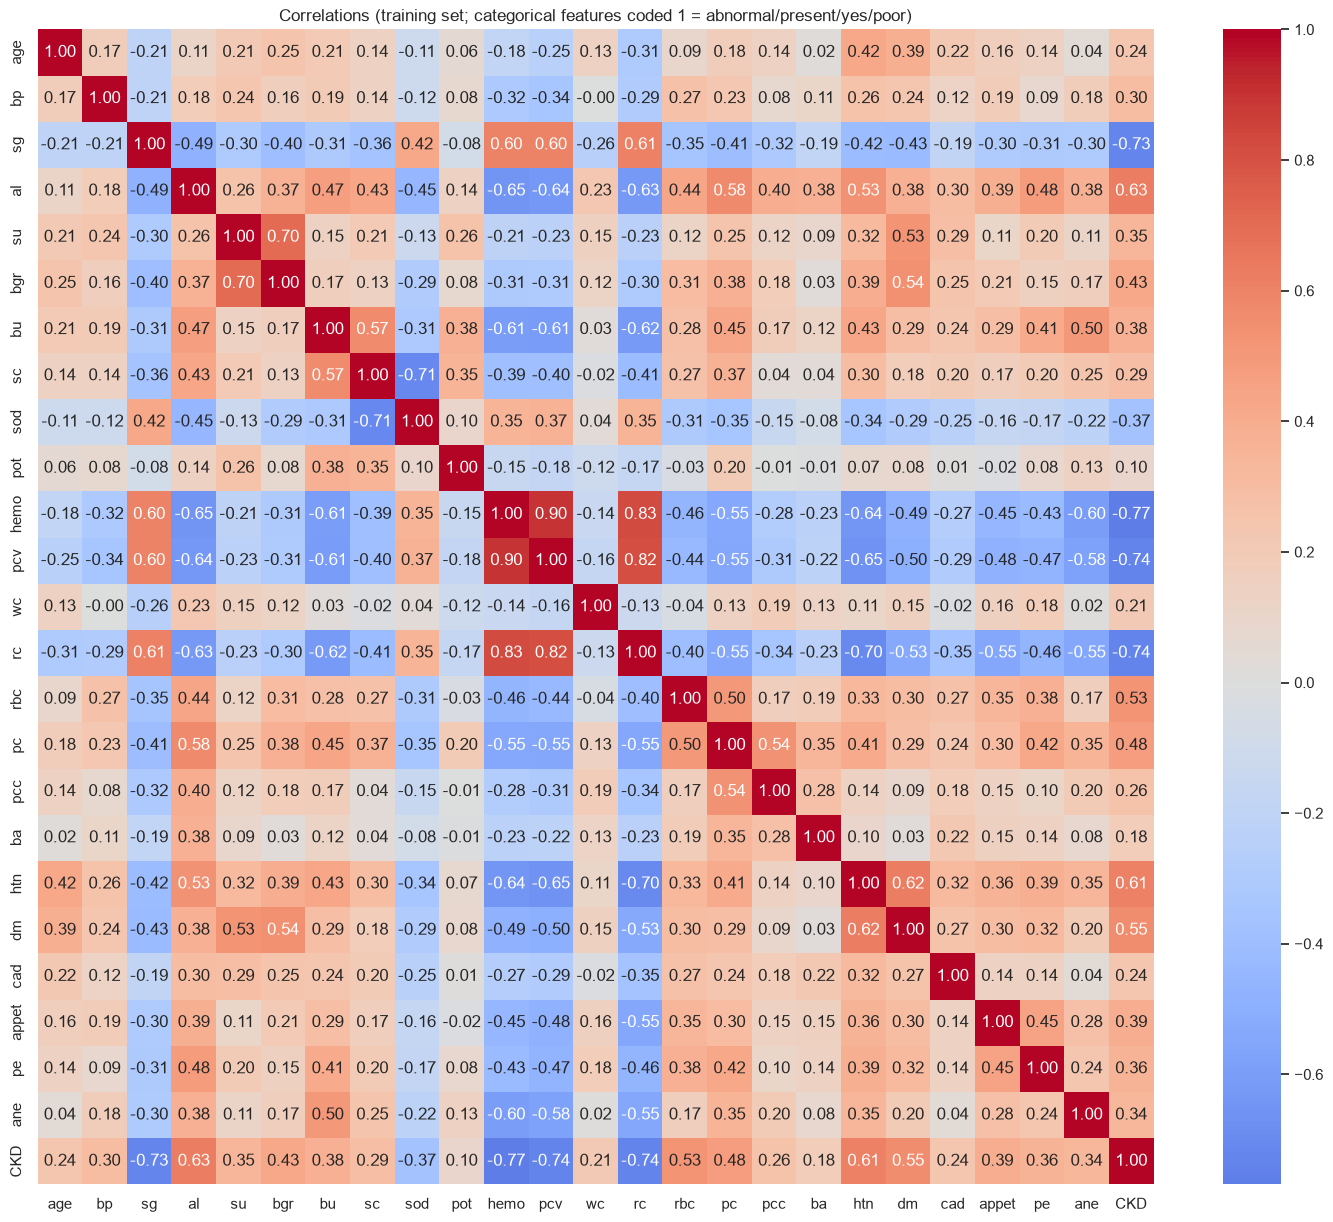

In [10]:
encoded = train_df[NUMERIC].copy()
for col in CATEGORICAL:
    encoded[col] = train_df[col].map({"abnormal": 1, "present": 1, "yes": 1, "poor": 1,
                                      "normal": 0, "notpresent": 0, "no": 0, "good": 0})
encoded["CKD"] = y_train
plt.figure(figsize=(18, 15))
sns.heatmap(encoded.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlations (training set; categorical features coded 1 = abnormal/present/yes/poor)")
plt.show()

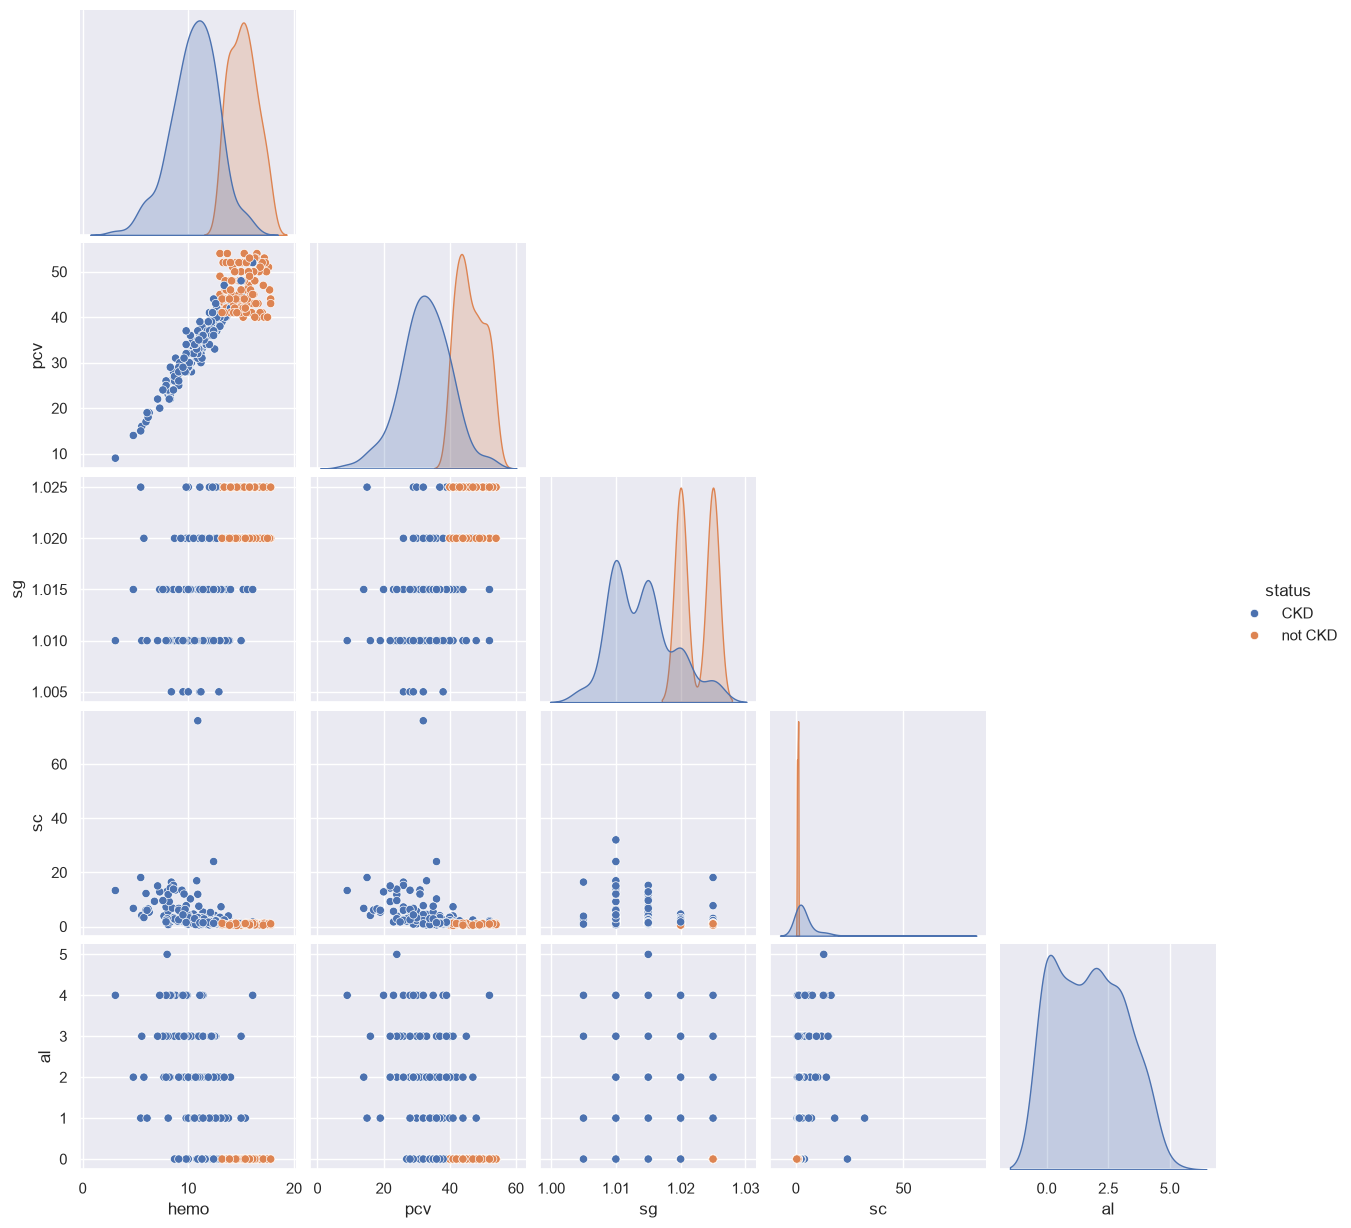

In [11]:
sns.pairplot(train_df[["hemo", "pcv", "sg", "sc", "al", "status"]], hue="status", corner=True)
plt.show()

Haemoglobin (`hemo`), packed cell volume (`pcv`), specific gravity (`sg`), serum creatinine (`sc`) and albumin (`al`)
separate the classes almost on their own. That is why most models below score close to 100%: the dataset is
genuinely easy, not just leaky.

## Preprocessing pipeline

Everything below is fitted inside the pipeline, on the training rows only:

| Step | What it does |
|:--|:--|
| Impute | median for numeric columns, most frequent value for categorical ones |
| Encode | one-hot encoding (each categorical column is binary, so one 0/1 column each) |
| Oversample | `RandomOverSampler` duplicates minority-class rows, **training data only** (imblearn skips it at prediction time) |
| Scale | `MinMaxScaler` to [-1, 1] |
| Reduce (optional) | PCA keeping 95% of the variance, or LDA (one discriminant axis for two classes) |

In [12]:
def make_pipeline(classifier, reducer=None):
    """Preprocessing + optional PCA/LDA + classifier. Fitting it touches only the data passed to .fit()."""
    preprocess = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), NUMERIC),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("encode", OneHotEncoder(drop="if_binary", handle_unknown="ignore"))]), CATEGORICAL),
    ])
    steps = [("preprocess", preprocess),
             ("oversample", RandomOverSampler(random_state=SEED)),
             ("scale", MinMaxScaler(feature_range=(-1, 1)))]
    if reducer == "PCA":
        steps.append(("reduce", PCA(n_components=0.95)))
    elif reducer == "LDA":
        steps.append(("reduce", LinearDiscriminantAnalysis()))
    steps.append(("model", classifier))
    return ImbPipeline(steps)


probe = make_pipeline(LogisticRegression(), "PCA").fit(X_train, y_train)
print("features after encoding:", probe.named_steps["preprocess"].transform(X_train.head()).shape[1])
print("PCA components for 95% of the variance (fitted on training data):", probe.named_steps["reduce"].n_components_)

features after encoding: 24
PCA components for 95% of the variance (fitted on training data): 15


## Compare classifiers

The same nine models as before: logistic regression, a decision tree, two random forests, an RBF SVM, 3-nearest
neighbours, Gaussian and Bernoulli naive Bayes, and a hard-voting ensemble of the other eight. Each is evaluated
with PCA, with LDA, and on the scaled features without reduction.

In [13]:
def classifiers():
    models = {
        "Logistic Regression": LogisticRegression(C=0.4, max_iter=1000, solver="liblinear"),
        "Decision Tree": DecisionTreeClassifier(random_state=14),
        "Random Forest (Gini)": RandomForestClassifier(random_state=14),
        "Random Forest (Entropy)": RandomForestClassifier(criterion="entropy", random_state=14),
        "SVM (RBF)": SVC(probability=True, random_state=SEED),
        "KNN (k=3)": KNeighborsClassifier(n_neighbors=3),
        "Gaussian NB": GaussianNB(),
        "Bernoulli NB": BernoulliNB(),
    }
    members = [(f"m{i}", clone(m)) for i, m in enumerate(models.values())]
    models["Voting (hard)"] = VotingClassifier(members, voting="hard")
    return models


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
rows, fitted = [], {}
for reducer in ["PCA", "LDA", None]:
    for name, clf in classifiers().items():
        pipe = make_pipeline(clf, reducer).fit(X_train, y_train)
        fitted[(reducer, name)] = pipe
        pred = pipe.predict(X_test)
        has_proba = hasattr(pipe, "predict_proba")
        scoring = ["accuracy", "f1"] + (["roc_auc"] if has_proba else [])
        scores = cross_validate(make_pipeline(clone(clf), reducer), X, y, cv=cv, scoring=scoring, n_jobs=-1)
        rows.append({
            "reduction": reducer or "none",
            "model": name,
            "test accuracy": accuracy_score(y_test, pred),
            "test precision": precision_score(y_test, pred),
            "test recall": recall_score(y_test, pred),
            "test F1": f1_score(y_test, pred),
            "test ROC AUC": roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1]) if has_proba else np.nan,
            "CV accuracy mean": scores["test_accuracy"].mean(),
            "CV accuracy sd": scores["test_accuracy"].std(),
            "CV F1 mean": scores["test_f1"].mean(),
            "CV ROC AUC mean": scores["test_roc_auc"].mean() if has_proba else np.nan,
        })
results = pd.DataFrame(rows)
results.round(4)

,reduction,model,test accuracy,test precision,test recall,test F1,test ROC AUC,CV accuracy mean,CV accuracy sd,CV F1 mean,CV ROC AUC mean
0,PCA,Logistic Regression,0.9750,1.0000,0.96,0.9796,1.0000,0.9720,0.0147,0.9769,1.0000
1,PCA,Decision Tree,0.9875,0.9804,1.00,0.9901,0.9833,0.9940,0.0094,0.9952,0.9947
2,PCA,Random Forest (Gini),1.0000,1.0000,1.00,1.0000,1.0000,0.9990,0.0049,0.9992,1.0000
3,PCA,Random Forest (Entropy),1.0000,1.0000,1.00,1.0000,1.0000,0.9995,0.0024,0.9996,1.0000
4,PCA,SVM (RBF),0.9750,1.0000,0.96,0.9796,1.0000,0.9825,0.0132,0.9857,1.0000
5,PCA,KNN (k=3),1.0000,1.0000,1.00,1.0000,1.0000,0.9855,0.0116,0.9882,0.9976
6,PCA,Gaussian NB,0.9750,1.0000,0.96,0.9796,1.0000,0.9900,0.0112,0.9919,1.0000
7,PCA,Bernoulli NB,0.9250,0.9783,0.90,0.9375,0.9613,0.9220,0.0258,0.9370,0.9806
8,PCA,Voting (hard),1.0000,1.0000,1.00,1.0000,NaN,0.9895,0.0110,0.9914,NaN
9,LDA,Logistic Regression,0.9750,1.0000,0.96,0.9796,0.9967,0.9700,0.0194,0.9751,0.9964


In [14]:
summary = results.assign(**{"CV accuracy": results["CV accuracy mean"].map("{:.3f}".format) + " ± "
                            + results["CV accuracy sd"].map("{:.3f}".format)})
summary.pivot(index="model", columns="reduction", values="CV accuracy")[["PCA", "LDA", "none"]]

reduction,PCA,LDA,none
model,,,
Bernoulli NB,0.922 ± 0.026,0.939 ± 0.020,0.952 ± 0.026
Decision Tree,0.994 ± 0.009,0.978 ± 0.017,0.969 ± 0.017
Gaussian NB,0.990 ± 0.011,0.976 ± 0.019,0.965 ± 0.012
KNN (k=3),0.985 ± 0.012,0.977 ± 0.015,0.983 ± 0.015
Logistic Regression,0.972 ± 0.015,0.970 ± 0.019,0.960 ± 0.018
Random Forest (Entropy),1.000 ± 0.002,0.978 ± 0.017,0.993 ± 0.008
Random Forest (Gini),0.999 ± 0.005,0.978 ± 0.017,0.993 ± 0.009
SVM (RBF),0.983 ± 0.013,0.975 ± 0.019,0.981 ± 0.012
Voting (hard),0.990 ± 0.011,0.976 ± 0.017,0.983 ± 0.014


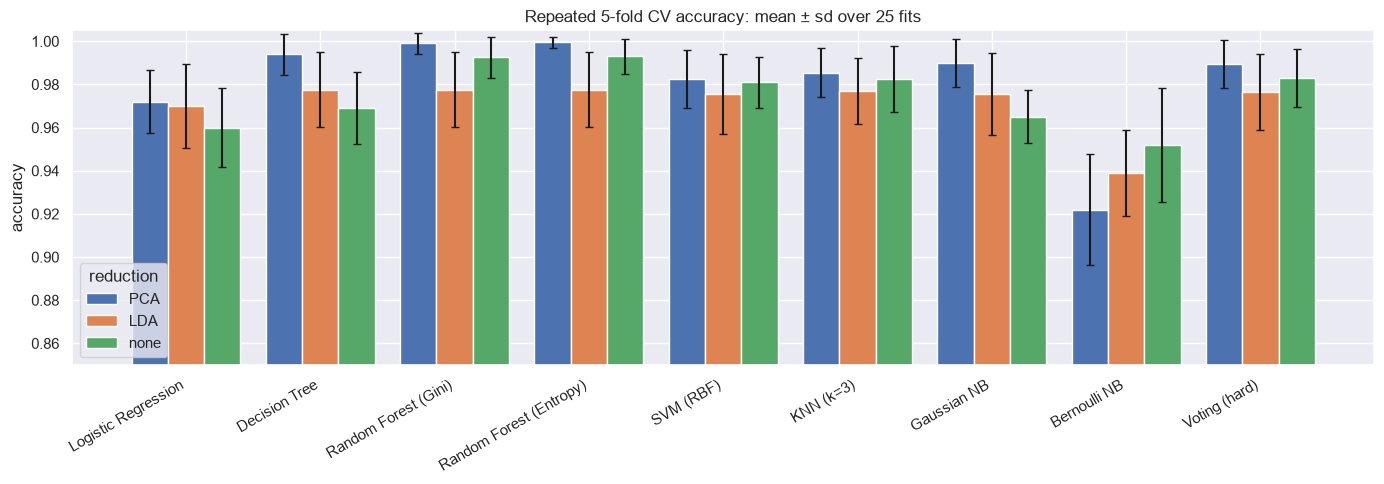

In [15]:
order = list(classifiers().keys())
xpos, width = np.arange(len(order)), 0.27
fig, ax = plt.subplots(figsize=(14, 5))
for i, reducer in enumerate(["PCA", "LDA", "none"]):
    sub = results[results["reduction"] == reducer].set_index("model").loc[order]
    ax.bar(xpos + (i - 1) * width, sub["CV accuracy mean"], width, yerr=sub["CV accuracy sd"], capsize=3,
           label=reducer)
ax.set_xticks(xpos, order, rotation=30, ha="right")
ax.set_ylim(0.85, 1.005)
ax.set_ylabel("accuracy")
ax.set_title("Repeated 5-fold CV accuracy: mean ± sd over 25 fits")
ax.legend(title="reduction")
plt.tight_layout()
plt.show()

## Held-out test set: confusion matrices and ROC curves (PCA pipelines)

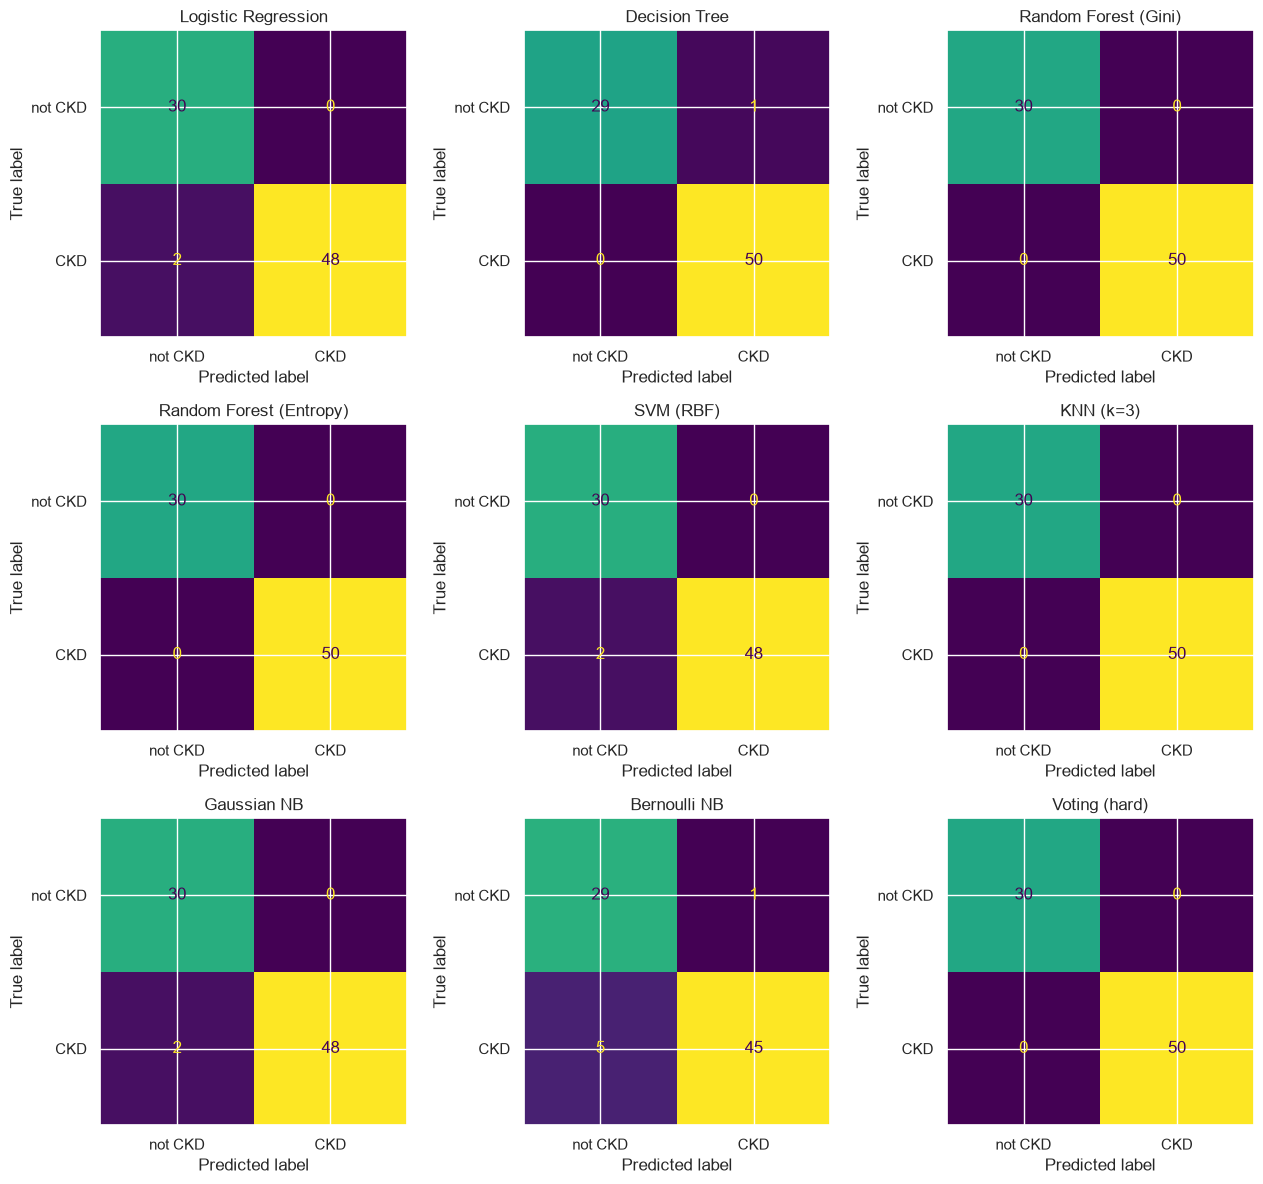

--- Logistic Regression (PCA) ---
              precision    recall  f1-score   support

     not CKD      0.938     1.000     0.968        30
         CKD      1.000     0.960     0.980        50

    accuracy                          0.975        80
   macro avg      0.969     0.980     0.974        80
weighted avg      0.977     0.975     0.975        80

--- Decision Tree (PCA) ---
              precision    recall  f1-score   support

     not CKD      1.000     0.967     0.983        30
         CKD      0.980     1.000     0.990        50

    accuracy                          0.988        80
   macro avg      0.990     0.983     0.987        80
weighted avg      0.988     0.988     0.987        80

--- Random Forest (Gini) (PCA) ---
              precision    recall  f1-score   support

     not CKD      1.000     1.000     1.000        30
         CKD      1.000     1.000     1.000        50

    accuracy                          1.000        80
   macro avg      1.000     1.0

              precision    recall  f1-score   support

     not CKD      1.000     1.000     1.000        30
         CKD      1.000     1.000     1.000        50

    accuracy                          1.000        80
   macro avg      1.000     1.000     1.000        80
weighted avg      1.000     1.000     1.000        80

--- SVM (RBF) (PCA) ---
              precision    recall  f1-score   support

     not CKD      0.938     1.000     0.968        30
         CKD      1.000     0.960     0.980        50

    accuracy                          0.975        80
   macro avg      0.969     0.980     0.974        80
weighted avg      0.977     0.975     0.975        80

--- KNN (k=3) (PCA) ---


              precision    recall  f1-score   support

     not CKD      1.000     1.000     1.000        30
         CKD      1.000     1.000     1.000        50

    accuracy                          1.000        80
   macro avg      1.000     1.000     1.000        80
weighted avg      1.000     1.000     1.000        80

--- Gaussian NB (PCA) ---
              precision    recall  f1-score   support

     not CKD      0.938     1.000     0.968        30
         CKD      1.000     0.960     0.980        50

    accuracy                          0.975        80
   macro avg      0.969     0.980     0.974        80
weighted avg      0.977     0.975     0.975        80

--- Bernoulli NB (PCA) ---
              precision    recall  f1-score   support

     not CKD      0.853     0.967     0.906        30
         CKD      0.978     0.900     0.938        50

    accuracy                          0.925        80
   macro avg      0.916     0.933     0.922        80
weighted avg      0.9

In [16]:
names = list(classifiers().keys())
fig, axes = plt.subplots(3, 3, figsize=(13, 12))
for ax, name in zip(axes.ravel(), names):
    ConfusionMatrixDisplay.from_predictions(y_test, fitted[("PCA", name)].predict(X_test), ax=ax, colorbar=False,
                                            display_labels=["not CKD", "CKD"])
    ax.set_title(name)
plt.tight_layout()
plt.show()

for name in names:
    print(f"--- {name} (PCA) ---")
    print(classification_report(y_test, fitted[("PCA", name)].predict(X_test), target_names=["not CKD", "CKD"],
                                digits=3))

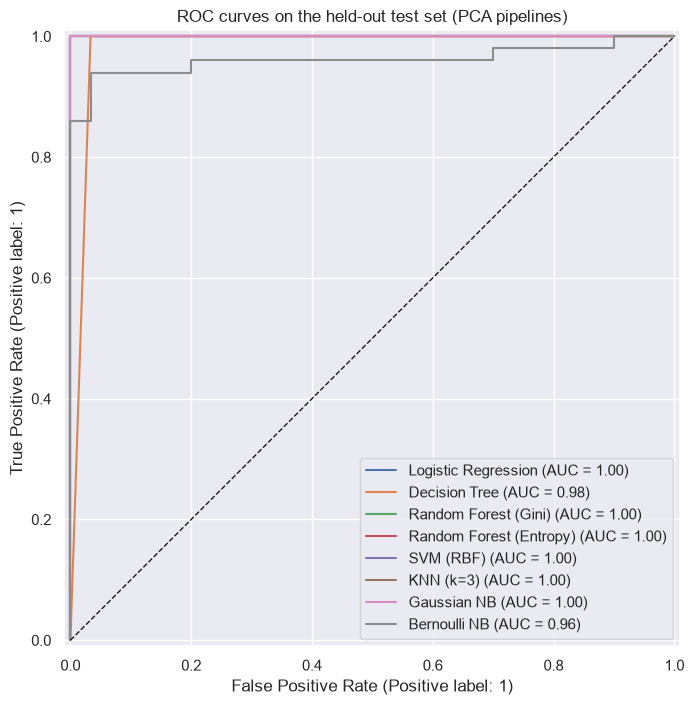

In [17]:
fig, ax = plt.subplots(figsize=(8, 8))
for name in names:
    pipe = fitted[("PCA", name)]
    if hasattr(pipe, "predict_proba"):
        RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_title("ROC curves on the held-out test set (PCA pipelines)")
plt.show()

## Tuning the random forest

Grid search with 10-fold stratified cross-validation **on the training rows only**. Because oversampling sits inside
the pipeline, each fold oversamples its own training part and is scored on untouched rows.

In [18]:
param_grid = {
    "model__n_estimators": list(range(7, 17)),
    "model__max_depth": [2, 3, 4, 5, 6, None],
    "model__class_weight": [None, "balanced"],
}
search = GridSearchCV(make_pipeline(RandomForestClassifier(criterion="entropy", random_state=42), "PCA"),
                      param_grid, cv=StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED),
                      scoring="f1", n_jobs=-1)
search.fit(X_train, y_train)
print("best parameters:", search.best_params_)
print("best 10-fold CV F1 on the training set: %.4f" % search.best_score_)

best = search.best_estimator_
pred = best.predict(X_test)
print("\nheld-out test set:")
print(classification_report(y_test, pred, target_names=["not CKD", "CKD"], digits=3))
print("confusion matrix [rows = true not CKD, CKD]:")
print(confusion_matrix(y_test, pred))
print("test ROC AUC: %.4f" % roc_auc_score(y_test, best.predict_proba(X_test)[:, 1]))

best parameters: {'model__class_weight': 'balanced', 'model__max_depth': 5, 'model__n_estimators': 10}
best 10-fold CV F1 on the training set: 1.0000

held-out test set:
              precision    recall  f1-score   support

     not CKD      1.000     1.000     1.000        30
         CKD      1.000     1.000     1.000        50

    accuracy                          1.000        80
   macro avg      1.000     1.000     1.000        80
weighted avg      1.000     1.000     1.000        80

confusion matrix [rows = true not CKD, CKD]:
[[30  0]
 [ 0 50]]
test ROC AUC: 1.0000


The neural-network version of this analysis is in `Neural_Networks_for_CKD_Prediction.ipynb`, which uses the same
split-first protocol.